In [1]:
from pylablib.devices import Thorlabs
import matplotlib.pyplot as plt
import os
import sys
import time
import socket
import threading
import csv
import numpy as np

from datetime import datetime
from ctypes import c_int16, c_int32, byref, c_char_p, c_float

from numpy.core.function_base import linspace
from picosdk.ps6000 import ps6000 as ps
from picosdk.functions import adc2mV, assert_pico_ok


# ---------------------------------------------------------------------
# Local component imports
# ---------------------------------------------------------------------

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

import Components as comp


# ---------------------------------------------------------------------
# Hardware setup
# ---------------------------------------------------------------------

laser = comp.Toptica_Laser()

powermeter = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0034379::INSTR',
    num_power_readings=15,
    bs_factor=1,
    wavelength=950
)

powermeter2 = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0046773::INSTR',
    num_power_readings=15,
    bs_factor=1,
    wavelength=950
)


from mdt69x import Controller
controller = Controller("COM4")

TopticaBackendError: backend exception: SerialException("could not open port 'COM5': PermissionError(13, 'Access is denied.', None, 5)") ('could not open port 'COM5': PermissionError(13, 'Access is denied.', None, 5)')

In [45]:
controller.set_x_voltage(23)

1

In [39]:
laser.set(0.047)

23.6
23.6
23.6
23.6
23.6
23.6
23.7
23.7
23.7
23.7
23.8
23.8
23.8
23.8
23.8
23.8
23.8
23.9
23.9
23.9
23.9
23.9
24.0
24.0
24.0
24.0
24.0
24.0
24.0
24.1
24.1
24.1
24.1
24.1
24.1
24.2
24.2
24.2
24.2
24.2
24.2
24.3
24.3
24.3
24.3
24.3
24.3
24.4
24.4
24.4
24.4
24.4
24.4
24.5
24.5
24.5
24.5
24.5
24.6
24.6
24.6
24.6
24.6
24.6
24.6
24.7
24.7
24.7
24.7
24.7
24.7
24.8
24.8
24.8
24.8
24.8
24.9
24.9
24.9
24.9
24.9
24.9
25.0
25.0
25.0
25.0
25.0
25.0
25.0
25.1
25.1
25.1
25.1
25.1
25.1
25.2
25.2
25.2
25.2
25.2
25.3
25.3
25.3
25.3
25.3
25.3
25.4
25.4
25.4
25.4
25.4
25.4
25.4
25.5
25.5
25.5
25.5
25.5
25.6
25.6
25.6
25.6
25.6
25.6
25.7
25.7
25.7
25.7
25.7
25.7
25.8
25.8
25.8
25.8
25.8
25.8
25.9
25.9
25.9
25.9
25.9
25.9
25.9
26.0
26.0
26.0
26.0
26.0
26.1
26.1
[2.8568293753333336, 0.13681460960000003, 0.10540023346666667, 0.10020561322666667, 0.0981524716266667, 0.10229245396666668, 0.09903880254, 0.10140609988, 0.10698217071999998, 1.5350353973333333, 1.574359468, 1.6711270139999999, 1.7448723086666666, 1

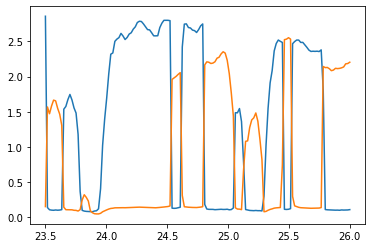

In [38]:
voltages = np.linspace(23.5,26,150)
poweroutx = []
powerouty = []
laser.set(0.027)


for x in voltages:
    power_reading = []
    power_reading_y = []
    controller.set_x_voltage(x)
    time.sleep(0.1)
    print(controller.get_x_voltage())
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        poweroutx.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
        powerouty.append(np.mean(np.array(power_reading_y)))

laser.set(0)
print(poweroutx)
print(powerouty)
print(voltages)
plt.plot(voltages,poweroutx)
plt.plot(voltages,powerouty)


14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
14.6
[16.009753626666665, 16.029794279999997, 16.090696233333336, 15.887616366666665, 15.558502133333333, 15.85031786, 16.250799433333334, 16.334079553333336, 16.338867026666666, 16.400325086666665, 16.3560133, 16.357349646666663, 16.34521334, 16.143915379999996, 15.674070046666664, 15.260005713333333, 14.91163075333333, 14.699866366666667, 14.428091706666669, 14.188938080000002, 13.791017480000002, 13.535497600000001, 13.309259273333334, 13.035369499999998, 12.725183, 12.426909366666665, 12.04279489

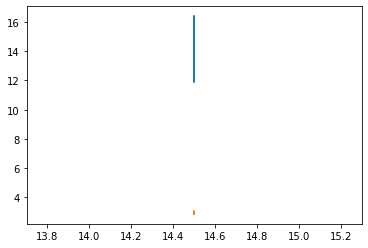

In [11]:
voltages = np.linspace(14.5,14.5,100)
poweroutx = []
powerouty = []
laser.set(0.06)


for x in voltages:
    power_reading = []
    power_reading_y = []
    controller.set_x_voltage(x)
    time.sleep(0.1)
    print(controller.get_x_voltage())
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        poweroutx.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
        powerouty.append(np.mean(np.array(power_reading_y)))

laser.set(0)
print(poweroutx)
print(powerouty)
print(voltages)
plt.plot(voltages,poweroutx)
plt.plot(voltages,powerouty)





In [16]:
controller.set_x_voltage(28.9)

1

In [2]:
laser.set(0.033)

NameError: name 'laser' is not defined

42.1
42.1
42.1
42.2
42.2
42.2
42.3
42.3
42.3
42.4
42.4
42.5
42.5
42.5
42.5
42.6
42.6
42.6
42.7
42.7
42.8
42.8
42.8
42.8
42.9
42.9
43.0
43.0
43.0
43.0
43.1
43.1
43.2
43.2
43.2
43.3
43.3
43.3
43.3
43.4
43.4
43.5
43.5
43.5
43.6
43.6
43.6
43.7
43.7
43.7
43.8
43.8
43.8
43.8
43.9
43.9
44.0
44.0
44.0
44.1
44.1
44.1
44.2
44.2
44.2
44.3
44.3
44.3
44.4
44.4
44.4
44.5
44.5
44.5
44.6
44.6
44.6
44.7
44.7
44.7
44.8
44.8
44.8
44.9
44.9
44.9
45.0
45.0
45.0
45.1
45.1
45.1
45.2
45.2
45.2
45.3
45.3
45.3
45.4
45.4
45.4
45.5
45.5
45.5
45.6
45.6
45.6
45.7
45.7
45.7
45.8
45.8
45.8
45.9
45.9
45.9
46.0
46.0
46.0
46.1
46.1
46.1
46.2
46.2
46.2
46.3
46.3
46.3
46.4
46.4
46.4
46.5
46.5
46.5
46.6
46.6
46.6
46.7
46.7
46.7
46.8
46.8
46.8
46.9
46.9
46.9
47.0
47.0
47.0
47.1
[4.277849410666667, 4.3350997353333325, 3.5670915320000005, 3.265613259333333, 2.8464670773333336, 2.733184511333333, 2.7045592259999998, 2.6055280313333333, 2.4035680786666664, 2.3754303280000006, 2.279078899333333, 2.093197765333333, 2.033633170666

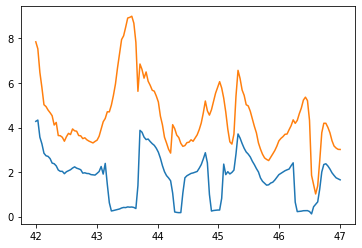

In [13]:
voltages = np.linspace(42,47,150)
poweroutx = []
powerouty = []
laser.set(0.033)


for x in voltages:
    power_reading = []
    power_reading_y = []
    controller.set_x_voltage(x)
    time.sleep(0.1)
    print(controller.get_x_voltage())
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        poweroutx.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
        powerouty.append(np.mean(np.array(power_reading_y)))

laser.set(0)
print(poweroutx)
print(powerouty)
print(voltages)
plt.plot(voltages,poweroutx)
plt.plot(voltages,powerouty)